# 05 – Interpretabilidade: o que mais influencia a previsão?

O notebook 04 mostrou **quanto** o modelo acerta. Este mostra **em que ele se baseia**: quais variáveis
pesam mais, em que direção e com que intensidade.

**Perguntas de negócio**
1. Quais variáveis mais influenciam o modelo?
2. Quais fatores estão mais associados à alfabetização?

**Técnicas** (aplicadas ao modelo final, LightGBM, nos municípios de teste)

| Técnica | O que mede | Limitação |
|---|---|---|
| **Importância nativa (gain)** | quanto cada variável melhora as divisões das árvores | interna ao modelo; favorece variáveis contínuas |
| **Importância por permutação** | quanto a ROC-AUC cai quando a variável é embaralhada | variáveis correlacionadas dividem a importância |
| **SHAP** | contribuição de cada variável para cada previsão, em direção e intensidade | mais custoso de calcular |

Para contornar a divisão entre variáveis correlacionadas, a permutação também é feita **por grupo**
(embaralhando o grupo inteiro de uma vez). A Regressão Logística serve de verificação de robustez.

**Base e modelo:** `base_alunos_2024` e o modelo salvo em `models/modelo_alunos_lgbm.joblib`, com a mesma
divisão treino/teste do notebook 04 (mesma semente).

> **Pré-requisito:** rode os notebooks 01 a 04 antes deste.

> **Como ler:** as importâncias descrevem o que o modelo usa para prever. São **associações**, não efeitos
> causais: indicam onde investigar, mas não comprovam o impacto de uma política.

In [1]:
# Configura o caminho do projeto para importar os módulos de src/.
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import shap
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

from src.config import RANDOM_STATE, REPORTS_DIR
from src.modeling.pipeline import (ALVO, CATEGORICAS, NUMERICAS, TERRITORIO_CAT, TERRITORIO_NUM, SOCIOECONOMICAS,
                                   HISTORICO_EDUCACIONAL, METAS, ALUNO_CAT, selecionar_X, criar_pipeline,
                                   modelos_candidatos)
from src.modeling.train import carregar_modelo, dividir_por_grupo, cv_por_grupo, otimizar, ESPACO_LOGISTICA
from src.visualization.style import (aplicar_estilo, salvar, AZUL, ESCALA_AZUL, LARANJA, CINZA, TEXTO_2,
                                     SEQ_AZUL)
from src.visualization.rotulos import rotulo
aplicar_estilo()

df = pd.read_parquet(ROOT / "data/processed/base_alunos_2024.parquet")
X, y, grupos = selecionar_X(df), df[ALVO], df["id_municipio"]
idx_tr, idx_te = dividir_por_grupo(X, y, grupos)          # mesma divisão do notebook 04 (mesma semente)
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
modelo = carregar_modelo("modelo_alunos_lgbm")
print(f"ROC-AUC do modelo carregado no teste: {roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1]):.4f}")

ROC-AUC do modelo carregado no teste: 0.6348


In [2]:
# Nomes das colunas após o pré-processamento e mapeamento de volta para a variável original.
prep = modelo[:-1]
nomes = list(modelo.named_steps["preprocessamento"].get_feature_names_out())
originais = NUMERICAS + CATEGORICAS + ["tem_rede_estadual", "dif_estadual_municipal_ant",
                                       "gap_rede_aluno_vs_uf_ant", "log_renda_per_capita"]
def variavel_original(n):
    n = n.replace("missingindicator_", "")
    for c in sorted(CATEGORICAS, key=len, reverse=True):
        if n.startswith(c + "_"):
            return c
    return n
mapa = {n: variavel_original(n) for n in nomes}
grupo_de = {**{v: "Aluno" for v in ALUNO_CAT}, **{v: "Território" for v in TERRITORIO_CAT + TERRITORIO_NUM},
            **{v: "Socioeconômicas" for v in SOCIOECONOMICAS + ["log_renda_per_capita"]},
            **{v: "Histórico 2023" for v in HISTORICO_EDUCACIONAL + ["tem_rede_estadual", "dif_estadual_municipal_ant",
                                                                     "gap_rede_aluno_vs_uf_ant"]},
            **{v: "Metas" for v in METAS}}
print(f"{len(nomes)} colunas após One-Hot e indicadores de ausência, vindas de {len(set(mapa.values()))} variáveis")

134 colunas após One-Hot e indicadores de ausência, vindas de 55 variáveis


## 1. Feature importance nativa (gain)

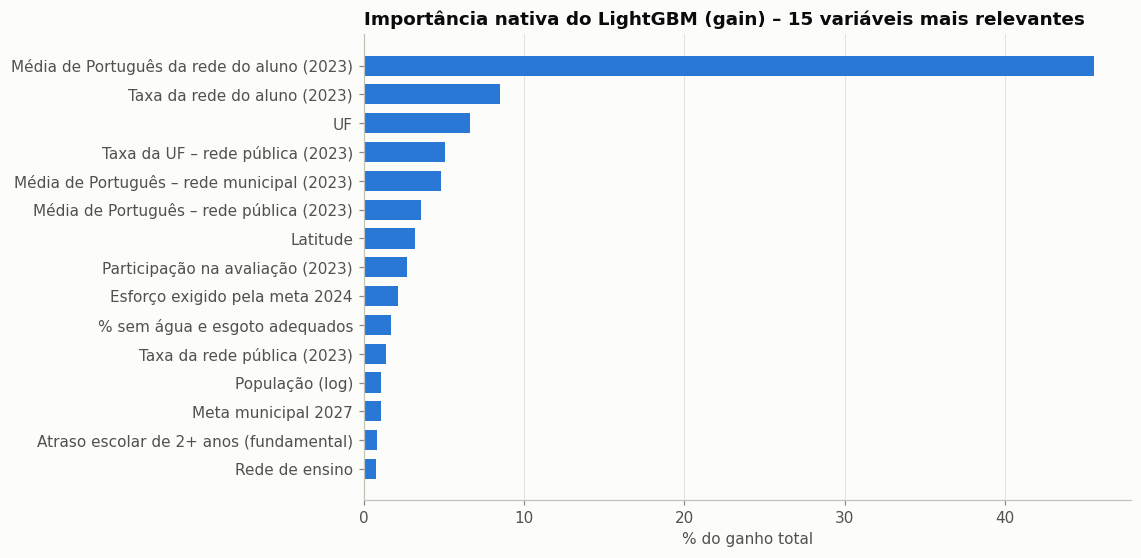

In [3]:
gain = pd.Series(modelo.named_steps["modelo"].booster_.feature_importance("gain"), index=nomes)
gain = gain.groupby(gain.index.map(mapa)).sum().sort_values(ascending=False)
gain = gain / gain.sum()
top = gain.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index.map(rotulo), top.values * 100, color=AZUL, height=0.7)
ax.set_xlabel("% do ganho total"); ax.grid(axis="y", visible=False)
ax.set_title("Importância nativa do LightGBM (gain) – 15 variáveis mais relevantes")
salvar(fig, "interp_01_importancia_gain")
plt.show()

## 2. Permutation importance (no teste)

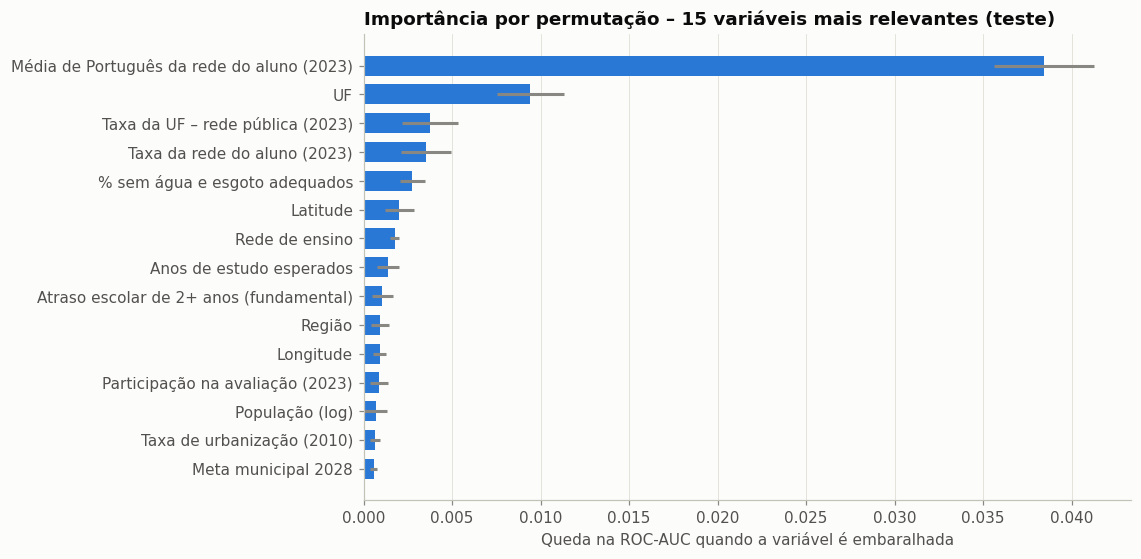

CPU times: total: 37.6 s
Wall time: 37.8 s


In [4]:
%%time
perm = permutation_importance(modelo, X_te, y_te, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm = pd.DataFrame({"queda_auc": perm.importances_mean, "desvio": perm.importances_std}, index=X_te.columns)
perm = perm.sort_values("queda_auc", ascending=False)
top = perm.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index.map(rotulo), top["queda_auc"], xerr=top["desvio"], color=AZUL, height=0.7, error_kw=dict(ecolor=CINZA))
ax.set_xlabel("Queda na ROC-AUC quando a variável é embaralhada"); ax.grid(axis="y", visible=False)
ax.set_title("Importância por permutação – 15 variáveis mais relevantes (teste)")
salvar(fig, "interp_02_permutation")
plt.show()

In [5]:
%%time
# Importância por GRUPO: embaralha todas as variáveis do grupo juntas (resolve a divisão entre correlacionadas).
rng = np.random.default_rng(RANDOM_STATE)
base_auc = roc_auc_score(y_te, modelo.predict_proba(X_te)[:, 1])
grupos_vars = {"Aluno (rede)": ALUNO_CAT, "Território": TERRITORIO_CAT + TERRITORIO_NUM,
               "Socioeconômicas": SOCIOECONOMICAS, "Histórico 2023": HISTORICO_EDUCACIONAL, "Metas": METAS}
imp_grupo = {}
for nome, cols in grupos_vars.items():
    quedas = []
    for _ in range(5):
        Xp = X_te.copy()
        perm_idx = rng.permutation(len(Xp))
        Xp[cols] = Xp[cols].values[perm_idx]
        quedas.append(base_auc - roc_auc_score(y_te, modelo.predict_proba(Xp)[:, 1]))
    imp_grupo[nome] = (np.mean(quedas), np.std(quedas))
imp_grupo = pd.DataFrame(imp_grupo, index=["queda_auc", "desvio"]).T.sort_values("queda_auc", ascending=False)
imp_grupo.round(4)

CPU times: total: 4.12 s
Wall time: 4.18 s


,queda_auc,desvio
Histórico 2023,0.0918,0.0040
Território,0.0211,0.0012
Socioeconômicas,0.0069,0.0005
Aluno (rede),0.0017,0.0010
Metas,-0.0001,0.0006


**Leitura**
- **O histórico de 2023 é o grupo que mais pesa:** embaralhá-lo derruba a ROC-AUC em 0,09.
- **O território vem em seguida** (queda de 0,02). As variáveis socioeconômicas, embaralhadas em bloco,
  reduzem pouco (0,007).
- **As metas não acrescentam nada.** O que elas informam provavelmente já está contido no histórico do
  município e na UF.

## 3. SHAP values

In [6]:
%%time
amostra = X_te.sample(4000, random_state=RANDOM_STATE)
Z = pd.DataFrame(prep.transform(amostra), columns=nomes, index=amostra.index)
explainer = shap.TreeExplainer(modelo.named_steps["modelo"])
sv = explainer.shap_values(Z)
sv = sv[1] if isinstance(sv, list) else sv
print("SHAP calculado para", sv.shape)

SHAP calculado para (4000, 134)
CPU times: total: 5.97 s
Wall time: 506 ms


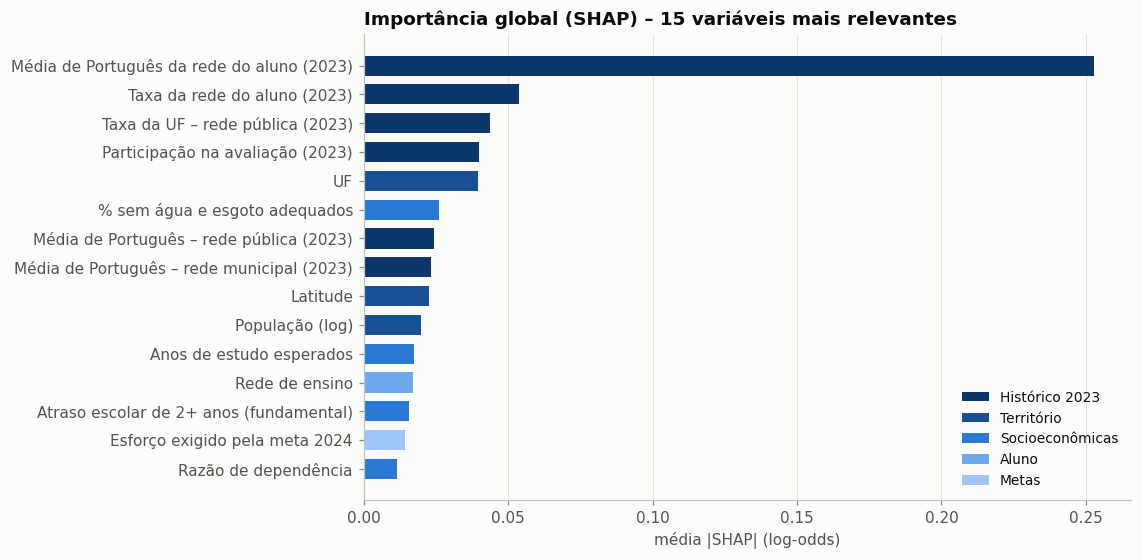

In [7]:
# Importância global: média do |SHAP| agregada por variável original (soma dos dummies da UF etc.).
shap_df = pd.DataFrame(sv, columns=nomes, index=Z.index)
shap_var = shap_df.T.groupby(lambda n: mapa[n]).sum().T          # contribuição por variável original
imp_shap = shap_var.abs().mean().sort_values(ascending=False)
imp_shap.to_frame("mean_abs_shap").assign(grupo=lambda d: d.index.map(grupo_de)).to_csv(REPORTS_DIR / "importancia_shap_alunos.csv")
top = imp_shap.head(15)[::-1]
# Degradê de azul: quanto mais escuro, mais o grupo pesa no modelo.
COR_GRUPO = dict(zip(["Histórico 2023", "Território", "Socioeconômicas", "Aluno", "Metas"], ESCALA_AZUL))
cores = top.index.map(lambda v: COR_GRUPO[grupo_de.get(v, "Território")])
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index.map(rotulo), top.values, color=cores, height=0.7)
ax.set_xlabel("média |SHAP| (log-odds)"); ax.grid(axis="y", visible=False)
ax.set_title("Importância global (SHAP) – 15 variáveis mais relevantes")
leg = list(COR_GRUPO)
ax.legend([plt.Rectangle((0, 0), 1, 1, color=COR_GRUPO[g]) for g in leg], leg,
          loc="lower right")
salvar(fig, "interp_03_shap_importancia")
plt.show()

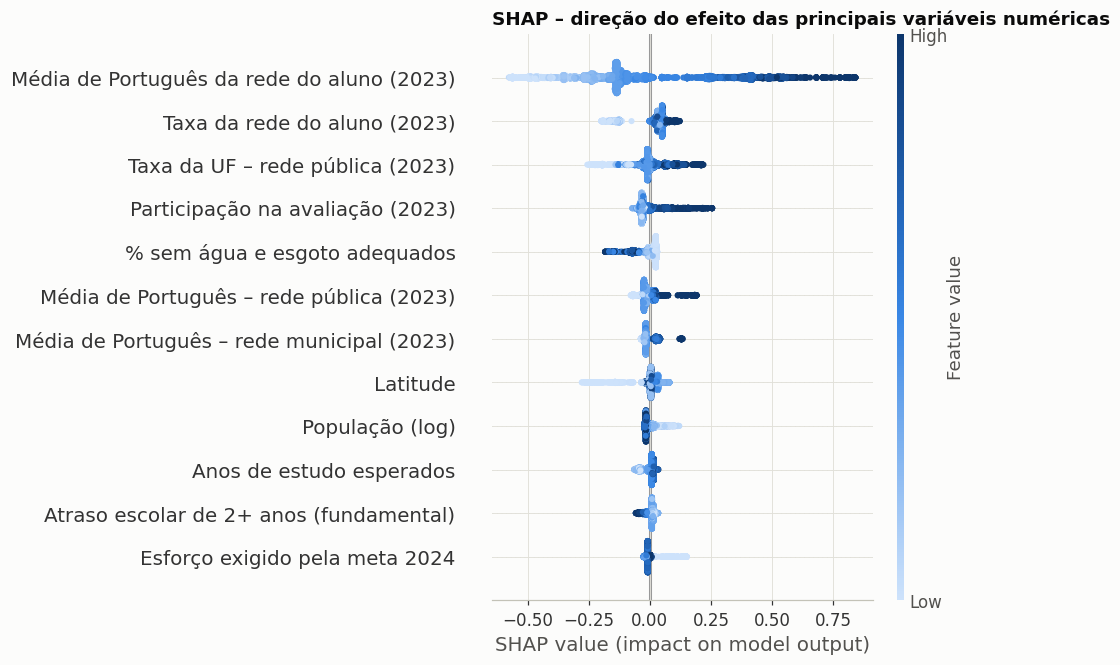

In [8]:
# Beeswarm: direção do efeito (cor = valor da variável; eixo = impacto na probabilidade de estar alfabetizado).
cols_num = [c for c in imp_shap.index if c in Z.columns][:12]
plt.figure()
shap.summary_plot(shap_df[cols_num].values, Z[cols_num], feature_names=[rotulo(c) for c in cols_num], show=False, plot_size=(9, 6), cmap=SEQ_AZUL)
plt.title("SHAP – direção do efeito das principais variáveis numéricas", loc="left", fontweight="bold")
salvar(plt.gcf(), "interp_04_shap_beeswarm")
plt.show()

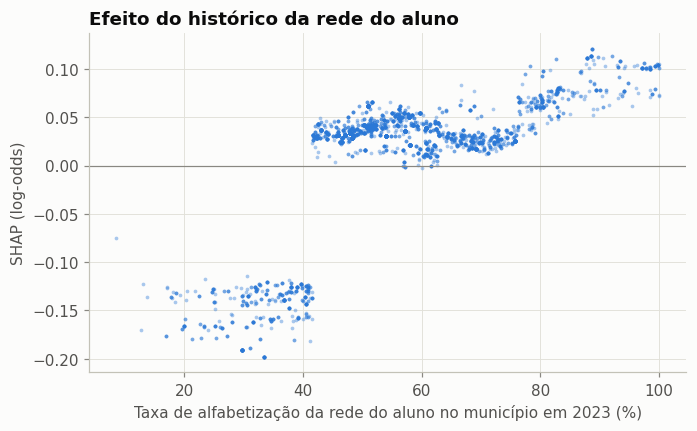

In [9]:
# Dependência: como a taxa da rede do aluno em 2023 se traduz em probabilidade.
v = "taxa_rede_aluno_ant"
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(amostra[v], shap_var[v], s=6, alpha=0.4, color=AZUL, linewidths=0)
ax.axhline(0, color=CINZA, linewidth=0.8)
ax.set_xlabel("Taxa de alfabetização da rede do aluno no município em 2023 (%)")
ax.set_ylabel("SHAP (log-odds)")
ax.set_title("Efeito do histórico da rede do aluno")
salvar(fig, "interp_05_dependencia_historico")
plt.show()

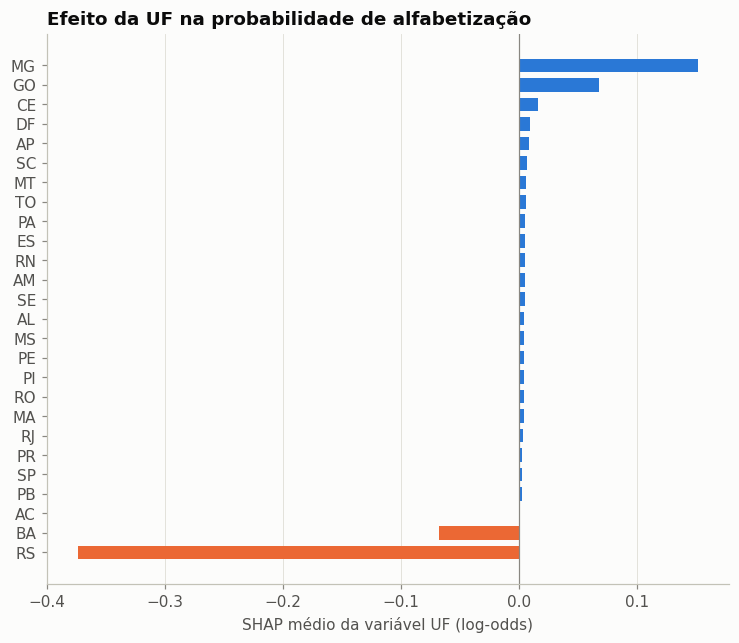

In [10]:
# Efeito médio de cada UF (soma dos SHAP dos dummies de UF), ordenado.
efeito_uf = shap_var["sigla_uf"].groupby(amostra["sigla_uf"]).mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(efeito_uf.index, efeito_uf.values, color=np.where(efeito_uf > 0, AZUL, LARANJA), height=0.7)
ax.axvline(0, color=CINZA, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("SHAP médio da variável UF (log-odds)")
ax.set_title("Efeito da UF na probabilidade de alfabetização")
salvar(fig, "interp_06_shap_uf")
plt.show()

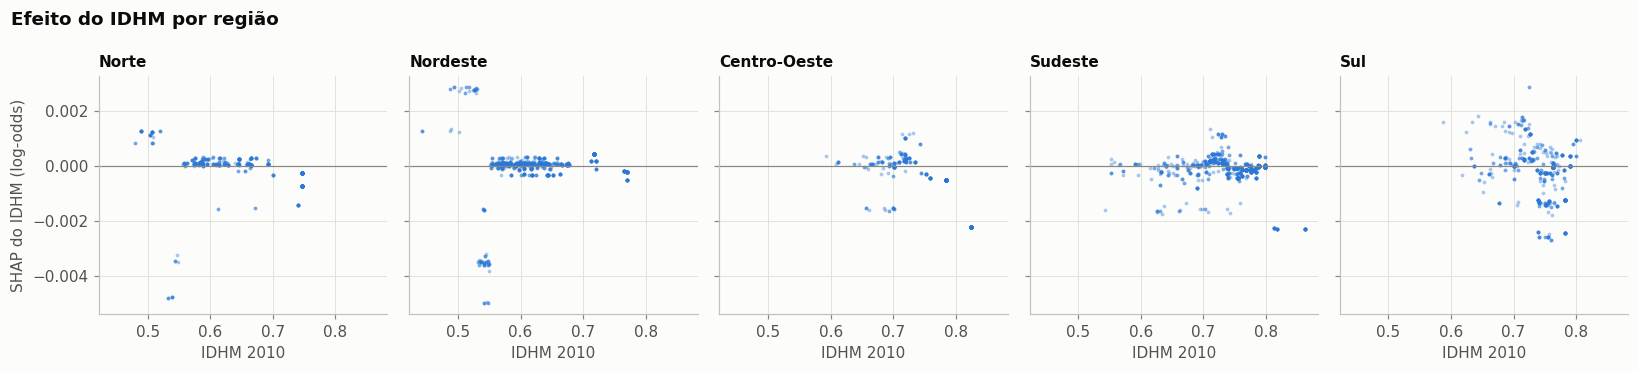

In [11]:
# Interação: o efeito do IDHM muda conforme a região? (SHAP do IDHM por região, um painel por região)
v = "idhm"
regioes = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4), sharex=True, sharey=True)
for ax, reg in zip(axes, regioes):
    m = amostra["regiao"] == reg
    ax.scatter(amostra.loc[m, v], shap_var.loc[m, v], s=6, alpha=0.4, color=AZUL, linewidths=0)
    ax.axhline(0, color=CINZA, linewidth=0.8)
    ax.set_title(reg, fontsize=10); ax.set_xlabel("IDHM 2010")
axes[0].set_ylabel("SHAP do IDHM (log-odds)")
fig.suptitle("Efeito do IDHM por região", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
salvar(fig, "interp_07_shap_idhm_regiao")
plt.show()

In [12]:
# Explicação local: um aluno com alta e outro com baixa probabilidade prevista.
proba_amostra = modelo.predict_proba(amostra)[:, 1]
for descricao, i in [("MENOR probabilidade", np.argmin(proba_amostra)), ("MAIOR probabilidade", np.argmax(proba_amostra))]:
    contrib = shap_var.iloc[i].sort_values(key=abs, ascending=False).head(6)
    print(f"Aluno com {descricao}: {proba_amostra[i]:.1%} | UF {amostra['sigla_uf'].iloc[i]} | "
          f"rede {amostra['rede_ensino'].iloc[i]} | taxa da rede em 2023: {amostra['taxa_rede_aluno_ant'].iloc[i]:.1f}%")
    print(contrib.rename(index=rotulo).round(3).to_string(), "\n")

Aluno com MENOR probabilidade: 28.9% | UF BA | rede Municipal | taxa da rede em 2023: 19.7%
Média de Português da rede do aluno (2023)   -0.561
Taxa da UF – rede pública (2023)             -0.222
Taxa da rede do aluno (2023)                 -0.169
Média de Português – rede pública (2023)     -0.066
UF                                           -0.055
Anos de estudo esperados                     -0.048 

Aluno com MAIOR probabilidade: 93.8% | UF CE | rede Municipal | taxa da rede em 2023: 99.4%
Média de Português da rede do aluno (2023)    0.840
Participação na avaliação (2023)              0.236
Taxa da UF – rede pública (2023)              0.206
Média de Português – rede pública (2023)      0.186
Taxa da rede pública (2023)                   0.139
Esforço exigido pela meta 2024                0.132 



## 4. Verificação de robustez: coeficientes da Regressão Logística

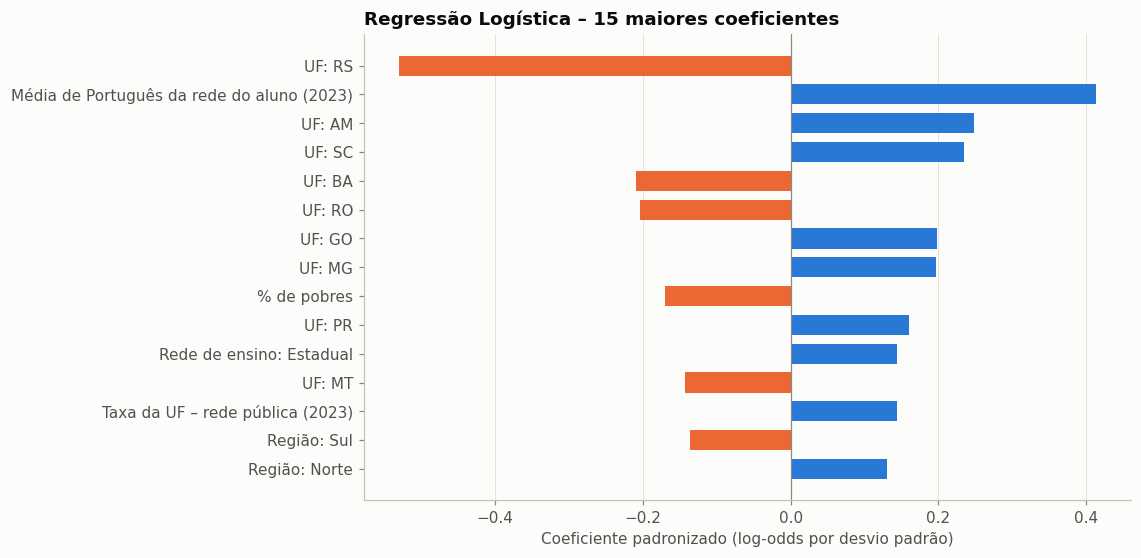

CPU times: total: 13.7 s
Wall time: 42.5 s


In [13]:
%%time
g_tr = grupos.iloc[idx_tr]
log = otimizar(criar_pipeline(modelos_candidatos()["Regressão Logística"]), ESPACO_LOGISTICA, X_tr, y_tr, g_tr, n_iter=8).best_estimator_
coef = pd.Series(log.named_steps["modelo"].coef_[0], index=log.named_steps["preprocessamento"].get_feature_names_out())
coef = coef[~coef.index.str.startswith("missingindicator")]
top = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(top.index.map(rotulo), top.values, color=np.where(top > 0, AZUL, LARANJA), height=0.7)
ax.axvline(0, color=CINZA, linewidth=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente padronizado (log-odds por desvio padrão)")
ax.set_title("Regressão Logística – 15 maiores coeficientes")
salvar(fig, "interp_08_coef_logistica")
plt.show()

## 5. Respostas às perguntas de negócio

**Quais variáveis mais influenciam o modelo?**
As três técnicas e os coeficientes da Regressão Logística apontam na mesma direção:
1. **Histórico de 2023 da rede do aluno.** Principalmente a média de Português da rede no município
   (`media_rede_aluno_ant`), seguida da taxa de alfabetização dessa rede. É o grupo que mais pesa:
   embaralhá-lo derruba a ROC-AUC em 0,09.
2. **Resultado do estado em 2023** (`taxa_uf_publica_ant`) e **participação do município na avaliação**
   (`participacao_ant`). Redes com participação alta tiveram, em média, alunos com maior probabilidade de
   alfabetização.
3. **A UF**, além do que o histórico já explica. O destaque é o **Rio Grande do Sul**, com efeito fortemente
   negativo: a taxa do estado caiu de 63% em 2023 para 45% em 2024. A queda coincide com as enchentes de
   abril e maio de 2024, que interromperam as aulas em boa parte do estado. O modelo captou essa queda pela
   variável UF, a partir dos resultados de 2024; nenhuma variável de 2023 poderia antecipá-la.
4. **Variáveis socioeconômicas, com peso menor.** Saneamento inadequado, distorção idade-série e menor
   escolaridade esperada aparecem associados a probabilidades menores. O IDHM quase não é usado depois que
   o histórico entra no modelo, provavelmente porque o que ele informa já está refletido no desempenho
   passado da rede.

**Quais fatores estão mais associados à alfabetização?**
- **O desempenho passado da rede.** Onde a rede já alfabetizava bem, os alunos tiveram chance muito maior
  de se alfabetizar. Uma hipótese é que fatores de gestão pedagógica (formação de professores, material,
  acompanhamento) mudam devagar e ficam registrados nesse histórico. Esta análise não testa essa causa.
- **O contexto estadual.** As diferenças entre UFs são grandes e não acompanham a riqueza, o que é
  compatível com o papel de políticas estaduais de alfabetização em colaboração com os municípios.
- **Choques externos.** O caso do RS sugere que um evento externo pode reverter rapidamente o avanço de um
  estado, o que reforça a importância de monitorar o resultado todo ano.
- **A vulnerabilidade socioeconômica**, associada a resultados piores, mas com peso menor que os fatores
  acima. Há municípios pobres que alfabetizam bem, como os do Ceará.

> **Importante:** as importâncias e o SHAP descrevem o que o *modelo* usa para prever. São **associações**,
> não efeitos causais: indicam onde investigar, mas não comprovam o impacto de uma política. Como as
> variáveis são do município e da rede, as explicações individuais da seção 3 descrevem, na prática, a rede
> do aluno.